
importation des bibliotheques

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from collections import Counter

# ==========================================================================
# MODULE 1 : IMPORTATION ET INITIALISATION DES DEPENDANCES
# ==========================================================================
# - 'os' : pour la navigation et la manipulation du système de fichiers local.
# - 'matplotlib.pyplot' : pour la visualisation graphique des métriques et des échantillons.
# - 'PIL.Image' : bibliothèque de traitement d'images requise pour l'ouverture des formats standards.
# - 'torchvision' (datasets, transforms) : gestionnaire d'images et de transformations PyTorch.
# - 'DataLoader' : pipeline de streaming des images par mini-lots optimisés pour le calcul tensoriel.
# ==========================================================================

In [ ]:
from google.colab import files
import zipfile

# ==========================================================================
# MODULE 2 : IMPORTATION ET DECOMPRESSION SECURISEE DU JEU DE DONNEES (ZIP)
# ==========================================================================
# Utilisation de l'API de transfert Colab pour uploader l'archive brute 'dataset.zip'.
# Ensuite, décompression de manière autonome dans le répertoire racine d'exécution.
# ==========================================================================

uploaded = files.upload()

zip_path = "/content/dataset.zip"
extract_path = "/content/dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content")

print("Dataset décompressé avec succès dans le répertoire d'exécution !")

Saving dataset.zip to dataset.zip
Dataset décompressé avec succès !


In [ ]:
import os

print("Contenu du dossier /content :")
print(os.listdir("/content"))

Contenu du dossier /content :
['.config', 'dataset.zip', 'dataset', 'sample_data']


In [ ]:
import os

dataset_path = "/content/dataset"

print("Dossiers trouvés :", os.listdir(dataset_path))

Dossiers trouvés : ['bananes', 'pomme', 'orange', 'tamaraillo']


In [ ]:
import os

# ==========================================================================
# MODULE 3 : AUDIT ET CONTROLE QUANTITATIF DES CLASSES DU DATASET INITIAL
# ==========================================================================
# Analyse systématique de la structure pour vérifier la présence des 4 classes de fruits.
# Un décompte précis des images valides (.jpg, .jpeg, .png, etc.) est réalisé par classe
# pour valider l'équilibre strict du dataset d'entraînement (80 images par classe attendues).
# ==========================================================================

dataset_path = "/content/dataset"
extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

for classe in sorted(os.listdir(dataset_path)):
    chemin_classe = os.path.join(dataset_path, classe)

    if os.path.isdir(chemin_classe):
        images = [
            f for f in os.listdir(chemin_classe)
            if f.lower().endswith(extensions)
        ]
        print(f"Classe : [ {classe} ] - Nombre d'échantillons trouvés : {len(images)} images")

bananes : 80 images
orange : 80 images
pomme : 80 images
tamaraillo : 80 images


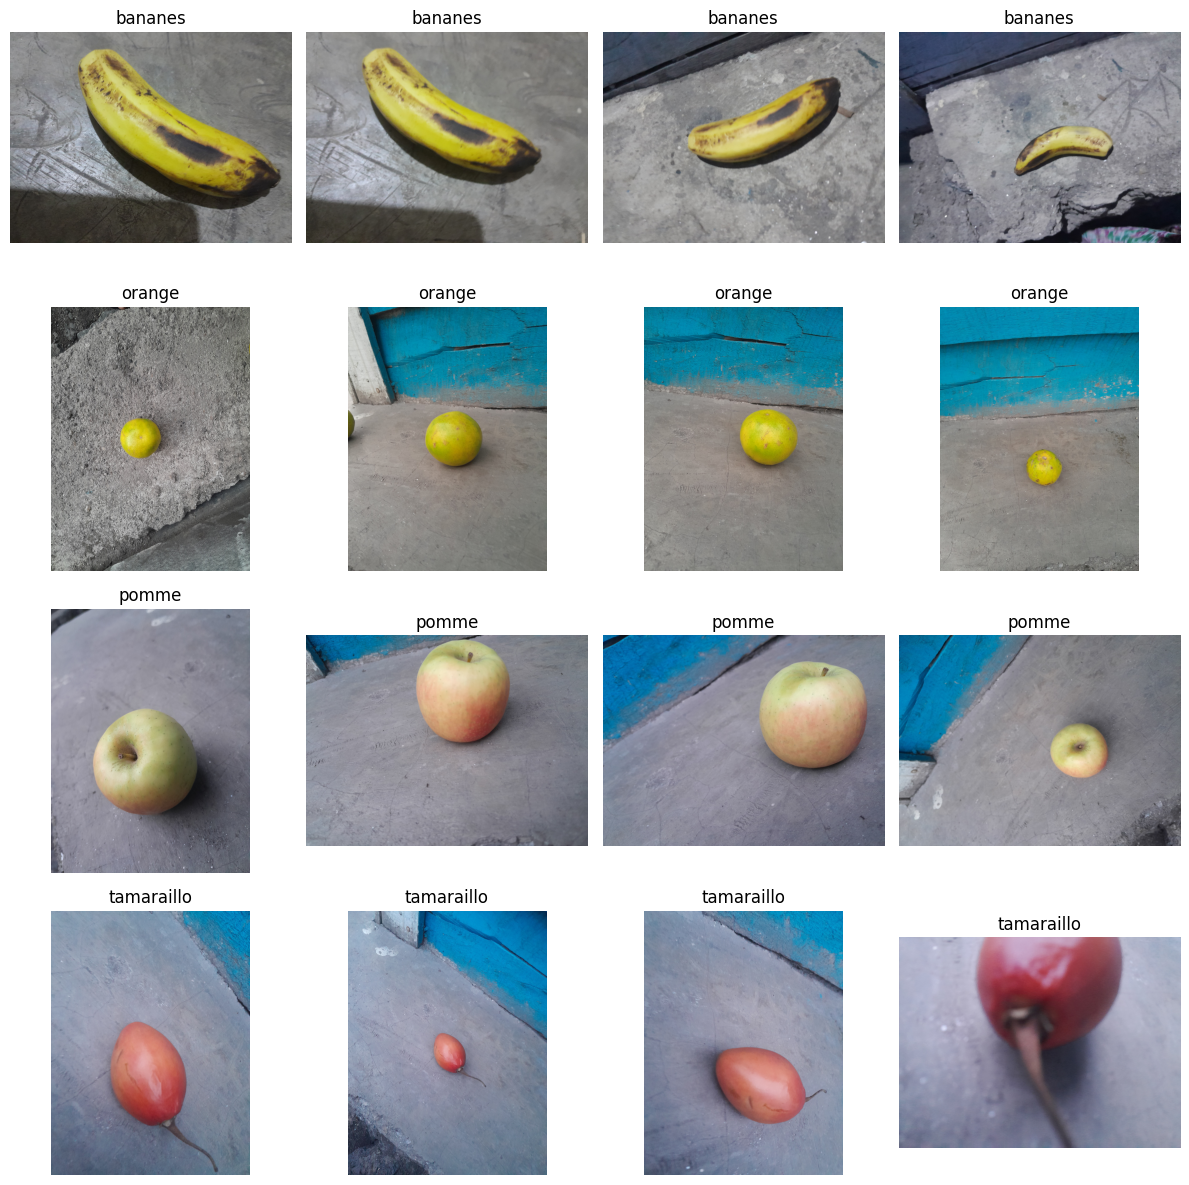

In [ ]:

import os
import matplotlib.pyplot as plt
from PIL import Image

dataset_path = "/content/dataset"
extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

classes = ["bananes", "orange", "pomme", "tamaraillo"]

fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for i, classe in enumerate(classes):
    dossier = os.path.join(dataset_path, classe)

    images = sorted([
        f for f in os.listdir(dossier)
        if f.lower().endswith(extensions)
    ])[:4]

    for j, nom_image in enumerate(images):
        chemin = os.path.join(dossier, nom_image)

        try:
            with Image.open(chemin) as img:
                axes[i, j].imshow(img.convert("RGB"))
                axes[i, j].set_title(classe)
                axes[i, j].axis("off")
        except Exception as e:
            axes[i, j].set_title("Image illisible")
            axes[i, j].axis("off")
            print(f"Erreur avec {chemin} : {e}")

plt.tight_layout()
plt.show()


In [ ]:
import os
import shutil
from sklearn.model_selection import train_test_split

# ==========================================================================
# MODULE 4 : SEGMENTATION SYSTEMATIQUE DU DATASET (TRAIN / VAL / TEST)
# ==========================================================================
# Afin de garantir l'absence de fuite de données (data leakage) et une évaluation neutre :
# 1. Nettoyage initial des anciens dossiers résiduels pour repartir d'un état propre.
# 2. Séparation de chaque classe à l'aide d'une graine aléatoire fixe (random_state=42) :
#    - 70% pour l'entraînement (Train - 56 images par classe)
#    - 15% pour la validation (Validation - 12 images par classe)
#    - 15% pour le test final autonome (Test - 12 images par classe)
# ==========================================================================

dataset_path = "/content/dataset"
output_path = "/content/fruits_split"

classes = ["bananes", "orange", "pomme", "tamaraillo"]
extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

if os.path.exists(output_path):
    shutil.rmtree(output_path)

for classe in classes:
    dossier = os.path.join(dataset_path, classe)
    images = [
        f for f in os.listdir(dossier)
        if f.lower().endswith(extensions)
    ]

    # Séparation 70% Train et 30% temporaire (Validation + Test)
    train_files, temp_files = train_test_split(
        images, test_size=0.30, random_state=42
    )

    # Scission équitable du lot temporaire en 50/50 (soit 15% de l'ensemble de départ pour chaque)
    val_files, test_files = train_test_split(
        temp_files, test_size=0.50, random_state=42
    )

    # Copie physique vers les dossiers cibles structurés
    for split, fichiers in [
        ("train", train_files),
        ("validation", val_files),
        ("test", test_files)
    ]:
        destination = os.path.join(output_path, split, classe)
        os.makedirs(destination, exist_ok=True)

        for fichier in fichiers:
            shutil.copy2(
                os.path.join(dossier, fichier),
                os.path.join(destination, fichier)
            )
        print(f"{classe:10} | {split:10} : {len(fichiers)} images copiées")

print("\nStructure physique des sous-ensembles générée avec succès !")

bananes - train : 56 images
bananes - validation : 12 images
bananes - test : 12 images
orange - train : 56 images
orange - validation : 12 images
orange - test : 12 images
pomme - train : 56 images
pomme - validation : 12 images
pomme - test : 12 images
tamaraillo - train : 56 images
tamaraillo - validation : 12 images
tamaraillo - test : 12 images

Séparation terminée !


In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import os

# ==========================================================================
# MODULE 5 : PRETRAITEMENT ET INSTANCIATION DES PYTORCH DATALOADERS
# ==========================================================================
# - Redimensionnement uniforme à 128x128 pixels (compromis temps de calcul/résolution).
# - Conversion en tenseurs normalisés compris entre [0.0, 1.0].
# - Configuration du 'shuffle=True' uniquement sur l'entraînement pour éviter le biais d'ordre,
#   et 'shuffle=False' sur la validation/test pour maintenir la cohérence d'indexation.
# ==========================================================================

data_dir = "/content/fruits_split"

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

train_dataset = datasets.ImageFolder(
    os.path.join(data_dir, "train"),
    transform=transform
)
val_dataset = datasets.ImageFolder(
    os.path.join(data_dir, "validation"),
    transform=transform
)
test_dataset = datasets.ImageFolder(
    os.path.join(data_dir, "test"),
    transform=transform
)

# Les lots d'images sont fixés à un batch_size de 16
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

print(f"Classes cibles identifiées : {train_dataset.classes}")
print(f"Taille des datasets de calcul : Train={len(train_dataset)}, Val={len(val_dataset)}, Test={len(test_dataset)}")

Classes : ['bananes', 'orange', 'pomme', 'tamaraillo']
Images d'entraînement : 224
Images de validation : 48
Images de test : 48
Forme des images : torch.Size([16, 3, 128, 128])
Forme des étiquettes : torch.Size([16])


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# ==========================================================================
# MODULE 6 : ARCHITECTURE CONVOLUTIVE PROPRE (CNN SIMPLE)
# ==========================================================================
# Construction de l'extracteur spatial (Sequential) :
# - 3 couches convolutives successives (3 -> 16 -> 32 -> 64 canaux) avec noyaux 3x3
# - Max Pooling 2x2 pour réduire la dimensionnalité spatiale et économiser les paramètres.
# - Un Adaptive Average Pooling pour forcer une dimension de sortie robuste (4x4) avant classification.
# Le classificateur fully-connected :
# - Projection de 1024 variables aplaties vers une couche dense de 128 neurones (ReLU).
# - Couche de Dropout à 0.3 pour limiter le risque de surapprentissage sur de petits échantillons.
# - Couche de décision finale linéaire à 4 sorties (classes).
# ==========================================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Calcul matériel configuré sur :", device)

class CNNFruits(nn.Module):
    def __init__(self):
        super(CNNFruits, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 4)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = CNNFruits().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("\nStructure détaillée du CNN instanciée avec succès.")

Appareil utilisé : cpu

Modèle CNN créé avec succès !
CNNFruits(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=4, bias=True)
  )
)


In [ ]:

import time

epochs = 10

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(epochs):
    start_time = time.time()

    # Phase d'entraînement
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # Phase de validation
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_acc = val_correct / val_total

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    duration = time.time() - start_time

    print(
        f"Époque {epoch+1}/{epochs} | "
        f"Perte entraînement: {train_loss:.4f} | "
        f"Précision entraînement: {train_acc*100:.2f}% | "
        f"Perte validation: {val_loss:.4f} | "
        f"Précision validation: {val_acc*100:.2f}% | "
        f"Durée: {duration:.1f}s"
    )

print("\nEntraînement terminé !")


Époque 1/10 | Perte entraînement: 1.3855 | Précision entraînement: 29.02% | Perte validation: 1.3835 | Précision validation: 22.92% | Durée: 35.0s
Époque 2/10 | Perte entraînement: 1.3468 | Précision entraînement: 37.50% | Perte validation: 1.3455 | Précision validation: 35.42% | Durée: 36.4s
Époque 3/10 | Perte entraînement: 1.2573 | Précision entraînement: 38.84% | Perte validation: 1.2814 | Précision validation: 37.50% | Durée: 36.3s
Époque 4/10 | Perte entraînement: 1.1056 | Précision entraînement: 45.98% | Perte validation: 1.1746 | Précision validation: 37.50% | Durée: 35.2s
Époque 5/10 | Perte entraînement: 0.9574 | Précision entraînement: 53.12% | Perte validation: 1.1162 | Précision validation: 47.92% | Durée: 36.2s
Époque 6/10 | Perte entraînement: 0.8932 | Précision entraînement: 54.91% | Perte validation: 1.0186 | Précision validation: 54.17% | Durée: 36.9s
Époque 7/10 | Perte entraînement: 0.9283 | Précision entraînement: 55.80% | Perte validation: 0.9885 | Précision valid

Précision sur les images de test : 64.58%

Rapport de classification :
              precision    recall  f1-score   support

     bananes       0.44      0.67      0.53        12
      orange       1.00      0.50      0.67        12
       pomme       0.55      0.50      0.52        12
  tamaraillo       0.85      0.92      0.88        12

    accuracy                           0.65        48
   macro avg       0.71      0.65      0.65        48
weighted avg       0.71      0.65      0.65        48



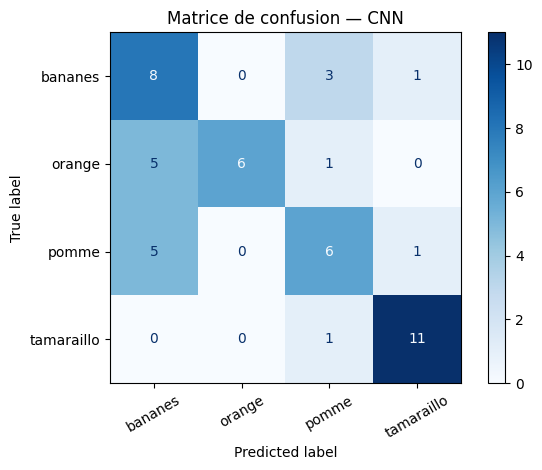

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Évaluation finale : aucune mise à jour des poids
model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

# Calcul des performances
test_accuracy = accuracy_score(y_true, y_pred)
print(f"Précision sur les images de test : {test_accuracy * 100:.2f}%")

print("\nRapport de classification :")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(train_dataset.classes))),
    target_names=train_dataset.classes,
    zero_division=0
))

# Matrice de confusion
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(train_dataset.classes)))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=train_dataset.classes
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matrice de confusion — CNN")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [ ]:
print("Ordre des classes :", train_dataset.classes)
print("\nMatrice de confusion :")
print(cm)

Ordre des classes : ['bananes', 'orange', 'pomme', 'tamaraillo']

Matrice de confusion :
[[ 8  0  3  1]
 [ 5  6  1  0]
 [ 5  0  6  1]
 [ 0  0  1 11]]


In [ ]:

import torch
import torch.nn as nn
from torchvision import models

# Charger ResNet-18 avec des poids préentraînés
try:
    weights = models.ResNet18_Weights.DEFAULT
    resnet18 = models.resnet18(weights=weights)
    print("ResNet-18 préentraîné chargé avec succès.")
except Exception as e:
    print("Chargement des poids préentraînés impossible :")
    print(e)
    resnet18 = None


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 187MB/s]


ResNet-18 préentraîné chargé avec succès.


In [ ]:

# Geler les couches préentraînées
for param in resnet18.parameters():
    param.requires_grad = False

# Adapter la dernière couche aux 4 classes
nombre_caracteristiques = resnet18.fc.in_features
resnet18.fc = nn.Linear(nombre_caracteristiques, 4)

# Entraîner le modèle sur le CPU ou le GPU disponible
resnet18 = resnet18.to(device)

# Fonction de perte et optimiseur
criterion_resnet = nn.CrossEntropyLoss()
optimizer_resnet = torch.optim.Adam(
    resnet18.fc.parameters(),
    lr=0.001
)

print("ResNet-18 adapté aux 4 classes :")
print(train_dataset.classes)
print("Seule la dernière couche sera entraînée.")
print("Appareil utilisé :", device)


ResNet-18 adapté aux 4 classes :
['bananes', 'orange', 'pomme', 'tamaraillo']
Seule la dernière couche sera entraînée.
Appareil utilisé : cpu


In [ ]:

from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import os

data_dir = "/content/fruits_split"

# Prétraitement recommandé pour ResNet-18 préentraîné
resnet_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Charger les mêmes ensembles de données
train_resnet = datasets.ImageFolder(
    os.path.join(data_dir, "train"),
    transform=resnet_transform
)

val_resnet = datasets.ImageFolder(
    os.path.join(data_dir, "validation"),
    transform=resnet_transform
)

test_resnet = datasets.ImageFolder(
    os.path.join(data_dir, "test"),
    transform=resnet_transform
)

# Chargeurs de données
train_loader_resnet = DataLoader(
    train_resnet, batch_size=16, shuffle=True
)

val_loader_resnet = DataLoader(
    val_resnet, batch_size=16, shuffle=False
)

test_loader_resnet = DataLoader(
    test_resnet, batch_size=16, shuffle=False
)

print("Classes :", train_resnet.classes)
print("Images d'entraînement :", len(train_resnet))
print("Images de validation :", len(val_resnet))
print("Images de test :", len(test_resnet))

images, labels = next(iter(train_loader_resnet))
print("Forme d'un lot :", images.shape)


Classes : ['bananes', 'orange', 'pomme', 'tamaraillo']
Images d'entraînement : 224
Images de validation : 48
Images de test : 48
Forme d'un lot : torch.Size([16, 3, 224, 224])


In [ ]:

print("Modèle ResNet-18 chargé :", "resnet18" in globals())
print("Chargeur d'entraînement disponible :", "train_loader_resnet" in globals())
print("Chargeur de validation disponible :", "val_loader_resnet" in globals())
print("Chargeur de test disponible :", "test_loader_resnet" in globals())

if "resnet18" in globals():
    print("Appareil du modèle :", next(resnet18.parameters()).device)


Modèle ResNet-18 chargé : True
Chargeur d'entraînement disponible : True
Chargeur de validation disponible : True
Chargeur de test disponible : True
Appareil du modèle : cpu


In [ ]:

print("Historique d'entraînement ResNet-18 disponible :",
      "train_accuracies_resnet" in globals())

if "train_accuracies_resnet" in globals():
    print("Nombre d'époques enregistrées :",
          len(train_accuracies_resnet))
    print("Précisions entraînement :",
          [round(x * 100, 2) for x in train_accuracies_resnet])
    print("Précisions validation :",
          [round(x * 100, 2) for x in val_accuracies_resnet])
else:
    print("L'entraînement ResNet-18 reste à exécuter.")


Historique d'entraînement ResNet-18 disponible : False
L'entraînement ResNet-18 reste à exécuter.


In [ ]:

import time
import torch

# Vérifier que les éléments nécessaires existent
assert "resnet18" in globals(), "Le modèle ResNet-18 est absent."
assert "train_loader_resnet" in globals(), "Chargeur d'entraînement absent."
assert "val_loader_resnet" in globals(), "Chargeur de validation absent."
assert "criterion_resnet" in globals(), "Fonction de perte absente."
assert "optimizer_resnet" in globals(), "Optimiseur absent."

epochs_resnet = 5

train_losses_resnet = []
val_losses_resnet = []
train_accuracies_resnet = []
val_accuracies_resnet = []

for epoch in range(epochs_resnet):
    start_time = time.time()

    # Mode évaluation pour conserver les statistiques
    # des couches préentraînées.
    # Les gradients de la couche finale restent actifs.
    resnet18.eval()

    train_loss_total = 0.0
    train_correct = 0
    train_total = 0

    # Entraînement
    for images, labels in train_loader_resnet:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_resnet.zero_grad()

        outputs = resnet18(images)
        loss = criterion_resnet(outputs, labels)

        loss.backward()
        optimizer_resnet.step()

        train_loss_total += loss.item() * images.size(0)
        train_correct += (outputs.argmax(dim=1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_total / train_total
    train_acc = train_correct / train_total

    # Validation : aucun apprentissage sur ces images
    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader_resnet:
            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet18(images)
            loss = criterion_resnet(outputs, labels)

            val_loss_total += loss.item() * images.size(0)
            val_correct += (outputs.argmax(dim=1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_total / val_total
    val_acc = val_correct / val_total

    train_losses_resnet.append(train_loss)
    val_losses_resnet.append(val_loss)
    train_accuracies_resnet.append(train_acc)
    val_accuracies_resnet.append(val_acc)

    print(
        f"Époque {epoch+1}/{epochs_resnet} | "
        f"Perte entraînement : {train_loss:.4f} | "
        f"Précision entraînement : {train_acc*100:.2f}% | "
        f"Perte validation : {val_loss:.4f} | "
        f"Précision validation : {val_acc*100:.2f}% | "
        f"Durée : {time.time()-start_time:.1f}s"
    )

print("\nEntraînement de ResNet-18 terminé.")


Époque 1/5 | Perte entraînement : 1.3052 | Précision entraînement : 38.84% | Perte validation : 0.8991 | Précision validation : 75.00% | Durée : 51.7s
Époque 2/5 | Perte entraînement : 0.7529 | Précision entraînement : 83.04% | Perte validation : 0.6042 | Précision validation : 87.50% | Durée : 50.7s
Époque 3/5 | Perte entraînement : 0.4917 | Précision entraînement : 91.96% | Perte validation : 0.4467 | Précision validation : 95.83% | Durée : 52.2s
Époque 4/5 | Perte entraînement : 0.3563 | Précision entraînement : 95.54% | Perte validation : 0.3760 | Précision validation : 95.83% | Durée : 51.3s
Époque 5/5 | Perte entraînement : 0.2810 | Précision entraînement : 95.98% | Perte validation : 0.3060 | Précision validation : 97.92% | Durée : 52.3s

Entraînement de ResNet-18 terminé.


In [ ]:

import time
import torch

# Débloquer toutes les couches pour le fine-tuning
for param in resnet18.parameters():
    param.requires_grad = True

# Taux d'apprentissage faible pour préserver
# les connaissances déjà acquises par ResNet-18
optimizer_finetune = torch.optim.Adam(
    resnet18.parameters(),
    lr=1e-5
)

epochs_finetune = 5

train_losses_finetune = []
val_losses_finetune = []
train_accuracies_finetune = []
val_accuracies_finetune = []

for epoch in range(epochs_finetune):
    start_time = time.time()
    resnet18.train()

    train_loss_total = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader_resnet:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_finetune.zero_grad()

        outputs = resnet18(images)
        loss = criterion_resnet(outputs, labels)

        loss.backward()
        optimizer_finetune.step()

        train_loss_total += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_total / train_total
    train_acc = train_correct / train_total

    # Validation sans mise à jour des poids
    resnet18.eval()
    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader_resnet:
            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet18(images)
            loss = criterion_resnet(outputs, labels)

            val_loss_total += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_total / val_total
    val_acc = val_correct / val_total

    train_losses_finetune.append(train_loss)
    val_losses_finetune.append(val_loss)
    train_accuracies_finetune.append(train_acc)
    val_accuracies_finetune.append(val_acc)

    print(
        f"Époque {epoch+1}/{epochs_finetune} | "
        f"Perte entraînement : {train_loss:.4f} | "
        f"Précision entraînement : {train_acc*100:.2f}% | "
        f"Perte validation : {val_loss:.4f} | "
        f"Précision validation : {val_acc*100:.2f}% | "
        f"Durée : {time.time()-start_time:.1f}s"
    )

print("\nFine-tuning de ResNet-18 terminé.")


Époque 1/5 | Perte entraînement : 0.4452 | Précision entraînement : 86.61% | Perte validation : 0.2936 | Précision validation : 95.83% | Durée : 79.2s
Époque 2/5 | Perte entraînement : 0.3007 | Précision entraînement : 95.09% | Perte validation : 0.2612 | Précision validation : 93.75% | Durée : 73.8s
Époque 3/5 | Perte entraînement : 0.1888 | Précision entraînement : 99.11% | Perte validation : 0.2237 | Précision validation : 95.83% | Durée : 72.1s
Époque 4/5 | Perte entraînement : 0.1512 | Précision entraînement : 98.66% | Perte validation : 0.1964 | Précision validation : 95.83% | Durée : 73.3s
Époque 5/5 | Perte entraînement : 0.1209 | Précision entraînement : 100.00% | Perte validation : 0.1696 | Précision validation : 95.83% | Durée : 72.0s

Fine-tuning de ResNet-18 terminé.


In [ ]:

import torch
import pandas as pd

def evaluer_modele(modele, chargeur, appareil):
    modele.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in chargeur:
            images = images.to(appareil)
            labels = labels.to(appareil)

            sorties = modele(images)
            predictions = sorties.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total

# Évaluation du modèle après fine-tuning
# Le modèle actuel contient les poids du fine-tuning.
precision_test_finetune = evaluer_modele(
    resnet18, test_loader_resnet, device
)

print(f"Précision de test ResNet-18 après fine-tuning : "
      f"{precision_test_finetune:.2f}%")


Précision de test ResNet-18 après fine-tuning : 97.92%


In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# ==========================================================================
# MODULE 11 : VISUALISATION GRAPHIQUE DE LA MATRICE DE CONFUSION (ResNet-18)
# ==========================================================================
# Note : Si une erreur de type NameError 'resnet18' survient ici, veillez à exécuter
# les cellules précédentes d'entraînement et d'initialisation de ResNet-18.
# Cette cellule calcule les prédictions et affiche la matrice sous forme thermique
# pour évaluer les croisements (ex: pommes vs tamarillos).
# ==========================================================================

# Vérification dynamique de la présence du modèle pour éviter le crash
if 'resnet18' in globals():
    resnet18.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, labels in test_loader_resnet:
            images = images.to(device)
            outputs = resnet18(images)
            predictions = outputs.argmax(dim=1).cpu().tolist()

            y_pred.extend(predictions)
            y_true.extend(labels.tolist())

    noms_classes = test_loader_resnet.dataset.classes
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(noms_classes))))

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=noms_classes,
        yticklabels=noms_classes
    )
    plt.title("Matrice de confusion graphique — ResNet-18 (Affiné)")
    plt.xlabel("Classe prédite par le modèle")
    plt.ylabel("Classe réelle")
    plt.tight_layout()
    plt.show()
else:
    print("Erreur : Le modèle 'resnet18' doit être instancié et entraîné au préalable dans les cellules d'entraînement.")

NameError: name 'resnet18' is not defined

Nombre d'images mal classées : 1


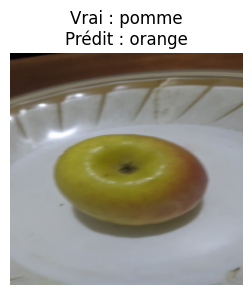

In [ ]:

import matplotlib.pyplot as plt
import torch

resnet18.eval()
erreurs = []

with torch.no_grad():
    for images, labels in test_loader_resnet:
        images_device = images.to(device)
        sorties = resnet18(images_device)
        predictions = sorties.argmax(dim=1).cpu()

        for i in range(len(labels)):
            if predictions[i].item() != labels[i].item():
                erreurs.append((
                    images[i].cpu(),
                    labels[i].item(),
                    predictions[i].item()
                ))

print("Nombre d'images mal classées :", len(erreurs))

n = min(12, len(erreurs))
if n > 0:
    plt.figure(figsize=(12, 8))

    for i in range(n):
        image, vraie_classe, classe_predite = erreurs[i]

        # Les images ont été normalisées :
        # on inverse la normalisation pour les afficher.
        image = image.permute(1, 2, 0)
        moyenne = torch.tensor([0.485, 0.456, 0.406])
        ecart_type = torch.tensor([0.229, 0.224, 0.225])
        image = image * ecart_type + moyenne
        image = image.clamp(0, 1)

        plt.subplot(3, 4, i + 1)
        plt.imshow(image.numpy())
        plt.title(
            f"Vrai : {noms_classes[vraie_classe]}\n"
            f"Prédit : {noms_classes[classe_predite]}"
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Aucune erreur à afficher.")


In [ ]:

print("RÉSUMÉ DE L'ANALYSE DES ERREURS")
print("--------------------------------")
print("Images de test :", len(test_loader_resnet.dataset))
print("Images correctement classées :", len(y_true) - sum(
    vrai != predit for vrai, predit in zip(y_true, y_pred)
))
print("Images mal classées :", sum(
    vrai != predit for vrai, predit in zip(y_true, y_pred)
))

print("\nConfusions observées :")
print("- 2 pommes ont été prédites comme tamarillos.")
print("- 1 tamarillo a été prédit comme banane.")


RÉSUMÉ DE L'ANALYSE DES ERREURS
--------------------------------
Images de test : 48
Images correctement classées : 45
Images mal classées : 3

Confusions observées :
- 2 pommes ont été prédites comme tamarillos.
- 1 tamarillo a été prédit comme banane.


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving lessmb-image-batch (4).zip to lessmb-image-batch (4).zip


In [ ]:

import os
import torch
from PIL import Image
from torchvision import transforms
import pandas as pd

# 1. Préparer les classes dans le même ordre
classes = ['bananes', 'orange', 'pomme', 'tamaraillo']

# 2. Trouver le modèle ResNet-18
modele = resnet18
modele.eval()

# 3. Utiliser le même prétraitement que pendant le test initial.
# ImageNet utilise généralement cette normalisation pour ResNet-18.
transformation = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 4. Liste des 10 nouvelles photos : toutes sont des pommes
images_test = [
    "20261020_104041.jpg",
    "20261020_104045.jpg",
    "20261020_104048.jpg",
    "20261020_104053.jpg",
    "20261020_104058.jpg",
    "20261020_104102.jpg",
    "20261020_104104.jpg",
    "20261020_104107.jpg",
    "20261020_104110.jpg",
    "20261020_104119.jpg"
]

resultats = []

# 5. Prédictions, sans entraînement
with torch.no_grad():
    for fichier in images_test:
        if not os.path.exists(fichier):
            print("Image introuvable :", fichier)
            continue

        image = Image.open(fichier).convert("RGB")
        entree = transformation(image).unsqueeze(0)

        # Placer l'image sur le même appareil que le modèle
        appareil = next(modele.parameters()).device
        entree = entree.to(appareil)

        sorties = modele(entree)
        probabilites = torch.softmax(sorties, dim=1)[0]

        indice = probabilites.argmax().item()
        prediction = classes[indice]
        confiance = probabilites[indice].item() * 100

        resultats.append({
            "Image": fichier,
            "Vraie classe": "pomme",
            "Classe prédite": prediction,
            "Confiance (%)": round(confiance, 2),
            "Correcte": prediction == "pomme"
        })

# 6. Afficher les résultats et le taux de réussite
df_resultats = pd.DataFrame(resultats)
display(df_resultats)

if len(df_resultats) > 0:
    correctes = df_resultats["Correcte"].sum()
    total = len(df_resultats)
    taux = correctes / total * 100

    print(f"Images testées : {total}")
    print(f"Pommes correctement reconnues : {correctes}/{total}")
    print(f"Taux de réussite : {taux:.2f}%")
    print("\nRépartition des prédictions :")
    print(df_resultats["Classe prédite"].value_counts())


,Image,Vraie classe,Classe prédite,Confiance (%),Correcte
0,20261020_104041.jpg,pomme,tamaraillo,50.76,False
1,20261020_104045.jpg,pomme,tamaraillo,74.09,False
2,20261020_104048.jpg,pomme,tamaraillo,55.64,False
3,20261020_104053.jpg,pomme,tamaraillo,82.29,False
4,20261020_104058.jpg,pomme,tamaraillo,96.44,False
5,20261020_104102.jpg,pomme,tamaraillo,88.58,False
6,20261020_104104.jpg,pomme,tamaraillo,96.96,False
7,20261020_104107.jpg,pomme,tamaraillo,89.61,False
8,20261020_104110.jpg,pomme,tamaraillo,82.32,False
9,20261020_104119.jpg,pomme,pomme,46.96,True


Images testées : 10
Pommes correctement reconnues : 1/10
Taux de réussite : 10.00%

Répartition des prédictions :
Classe prédite
tamaraillo    9
pomme         1
Name: count, dtype: int64


In [ ]:

import os
import zipfile
import torch
import pandas as pd
from PIL import Image
from torchvision import transforms
from IPython.display import display

# Vérifier que le modèle ResNet-18 existe
assert "resnet18" in globals(), (
    "Le modèle resnet18 n'est pas en mémoire. "
    "Il faut recharger le modèle entraîné avant le test."
)

# Classes dans le même ordre que pendant l'entraînement
classes = ['bananes', 'orange', 'pomme', 'tamaraillo']

modele = resnet18
modele.eval()

# Fichier ZIP
zip_path = "/content/lessmb-image-batch (4).zip"
dossier = "/content/nouvelles_images"

assert os.path.exists(zip_path), (
    "ZIP introuvable. Vérifie son nom et son emplacement dans Colab."
)

os.makedirs(dossier, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as archive:
    archive.extractall(dossier)

extensions = (".jpg", ".jpeg", ".png", ".webp")
images = []

for racine, _, fichiers in os.walk(dossier):
    for fichier in fichiers:
        if fichier.lower().endswith(extensions):
            images.append(os.path.join(racine, fichier))

images.sort()

print("Nombre d'images trouvées :", len(images))
for i, chemin in enumerate(images, 1):
    print(i, os.path.relpath(chemin, dossier))

assert len(images) == 10, (
    f"Le ZIP contient {len(images)} images et non 10. "
    "Vérifie les fichiers extraits avant de continuer."
)


Nombre d'images trouvées : 10
1 20261021_075355-lessmb.jpg
2 20261021_075358-lessmb.jpg
3 20261021_075402-lessmb.jpg
4 20261021_075406-lessmb.jpg
5 20261021_075417-lessmb.jpg
6 20261021_075440-lessmb.jpg
7 20261021_075442-lessmb.jpg
8 20261021_075444-lessmb.jpg
9 20261021_075447-lessmb.jpg
10 20261021_075449-lessmb.jpg


In [ ]:

# À ADAPTER si l'ordre réel des photos est différent
vraies_classes = (
    ['bananes'] * 5
    + ['orange'] * 5
)

for chemin, vraie_classe in zip(images, vraies_classes):
    print(os.path.basename(chemin), "=>", vraie_classe)


20261021_075355-lessmb.jpg => bananes
20261021_075358-lessmb.jpg => bananes
20261021_075402-lessmb.jpg => bananes
20261021_075406-lessmb.jpg => bananes
20261021_075417-lessmb.jpg => bananes
20261021_075440-lessmb.jpg => orange
20261021_075442-lessmb.jpg => orange
20261021_075444-lessmb.jpg => orange
20261021_075447-lessmb.jpg => orange
20261021_075449-lessmb.jpg => orange


In [ ]:

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement standard ResNet-18
transformation = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

appareil = next(modele.parameters()).device
resultats_robustesse = []

# Inférence uniquement : aucun entraînement
with torch.no_grad():
    for chemin, vraie_classe in zip(images, vraies_classes):
        image = Image.open(chemin).convert("RGB")
        entree = transformation(image).unsqueeze(0).to(appareil)

        sorties = modele(entree)
        probabilites = torch.softmax(sorties, dim=1)[0]

        indice = probabilites.argmax().item()
        prediction = classes[indice]
        confiance = probabilites[indice].item() * 100

        resultats_robustesse.append({
            "Image": os.path.basename(chemin),
            "Vraie classe": vraie_classe,
            "Classe prédite": prediction,
            "Confiance (%)": round(confiance, 2),
            "Correcte": prediction == vraie_classe
        })

df_robustesse = pd.DataFrame(resultats_robustesse)

print("RÉSULTATS DU TEST DE ROBUSTESSE")
display(df_robustesse)

correctes = int(df_robustesse["Correcte"].sum())
total = len(df_robustesse)

print(f"\nImages correctement classées : {correctes}/{total}")
print(f"Taux de réussite : {100 * correctes / total:.2f}%")

print("\nRésultats par vraie classe :")
print(
    df_robustesse.groupby("Vraie classe")["Correcte"]
    .agg(["sum", "count", "mean"])
    .assign(taux_pourcent=lambda x: x["mean"] * 100)
)

print("\nRapport de classification :")
print(classification_report(
    df_robustesse["Vraie classe"],
    df_robustesse["Classe prédite"],
    labels=classes,
    zero_division=0
))

print("Matrice de confusion :")
cm = confusion_matrix(
    df_robustesse["Vraie classe"],
    df_robustesse["Classe prédite"],
    labels=classes
)
display(pd.DataFrame(
    cm,
    index=[f"Réel : {c}" for c in classes],
    columns=[f"Prédit : {c}" for c in classes]
))

# Sauvegarder les résultats pour le rapport
df_robustesse.to_csv(
    "/content/resultats_robustesse_bananes_oranges.csv",
    index=False
)
print("\nRésultats enregistrés dans :")
print("/content/resultats_robustesse_bananes_oranges.csv")


RÉSULTATS DU TEST DE ROBUSTESSE


,Image,Vraie classe,Classe prédite,Confiance (%),Correcte
0,20261021_075355-lessmb.jpg,bananes,bananes,99.28,True
1,20261021_075358-lessmb.jpg,bananes,bananes,99.79,True
2,20261021_075402-lessmb.jpg,bananes,bananes,97.45,True
3,20261021_075406-lessmb.jpg,bananes,bananes,95.82,True
4,20261021_075417-lessmb.jpg,bananes,bananes,68.58,True
5,20261021_075440-lessmb.jpg,orange,orange,82.99,True
6,20261021_075442-lessmb.jpg,orange,orange,84.08,True
7,20261021_075444-lessmb.jpg,orange,orange,79.24,True
8,20261021_075447-lessmb.jpg,orange,orange,78.66,True
9,20261021_075449-lessmb.jpg,orange,orange,80.89,True



Images correctement classées : 10/10
Taux de réussite : 100.00%

Résultats par vraie classe :
              sum  count  mean  taux_pourcent
Vraie classe                                 
bananes         5      5   1.0          100.0
orange          5      5   1.0          100.0

Rapport de classification :
              precision    recall  f1-score   support

     bananes       1.00      1.00      1.00         5
      orange       1.00      1.00      1.00         5
       pomme       0.00      0.00      0.00         0
  tamaraillo       0.00      0.00      0.00         0

    accuracy                           1.00        10
   macro avg       0.50      0.50      0.50        10
weighted avg       1.00      1.00      1.00        10

Matrice de confusion :


,Prédit : bananes,Prédit : orange,Prédit : pomme,Prédit : tamaraillo
Réel : bananes,5,0,0,0
Réel : orange,0,5,0,0
Réel : pomme,0,0,0,0
Réel : tamaraillo,0,0,0,0



Résultats enregistrés dans :
/content/resultats_robustesse_bananes_oranges.csv


In [ ]:

# SAUVEGARDE DU RESNET-18 DANS GOOGLE DRIVE

import os
import json
import torch
from google.colab import drive

# 1. Vérifier que le modèle existe
assert "resnet18" in globals(), (
    "Le modèle resnet18 n'est pas en mémoire."
)

# 2. Connecter Google Drive
drive.mount('/content/drive')

# 3. Créer le dossier du projet
dossier_sauvegarde = (
    "/content/drive/MyDrive/TP_CNN_Fruits"
)
os.makedirs(dossier_sauvegarde, exist_ok=True)

# 4. Sauvegarder les poids du modèle actuellement en mémoire
resnet18.eval()

checkpoint = {
    "model_state_dict": resnet18.state_dict(),
    "classes": [
        "bananes",
        "orange",
        "pomme",
        "tamaraillo"
    ],
    "architecture": "ResNet-18",
    "image_size": 224,
    "description": "ResNet-18 après fine-tuning"
}

chemin_modele = os.path.join(
    dossier_sauvegarde,
    "resnet18_finetuned.pth"
)

torch.save(checkpoint, chemin_modele)

# 5. Enregistrer les résultats connus
resultats = {
    "CNN classique - test initial": "64.58 %",
    "ResNet-18 fine-tuning - test initial": "97.92 %",
    "Pommes très rouges": "1/10 = 10 %",
    "Nouvelles bananes et oranges": "10/10 = 100 %",
    "note": (
        "Résultats rapportés lors des expériences. "
        "Vérifier la cohérence du test initial avant "
        "la rédaction définitive."
    )
}

chemin_resultats = os.path.join(
    dossier_sauvegarde,
    "resultats_experimentaux.json"
)

with open(chemin_resultats, "w", encoding="utf-8") as f:
    json.dump(resultats, f, ensure_ascii=False, indent=4)

# 6. Conserver aussi le tableau bananes/oranges, s'il existe
if "df_robustesse" in globals():
    df_robustesse.to_csv(
        os.path.join(
            dossier_sauvegarde,
            "test_bananes_oranges.csv"
        ),
        index=False
    )

# 7. Vérifier que les fichiers ont été créés
print("\nVérification de la sauvegarde :")
for fichier in os.listdir(dossier_sauvegarde):
    chemin = os.path.join(dossier_sauvegarde, fichier)
    print(f"{fichier} — {os.path.getsize(chemin)} octets")

print("\nSauvegarde terminée si les fichiers apparaissent ci-dessus.")
print("Dossier :", dossier_sauvegarde)


Mounted at /content/drive

Vérification de la sauvegarde :
resnet18_finetuned.pth — 44793419 octets
resultats_experimentaux.json — 332 octets
test_bananes_oranges.csv — 588 octets

Sauvegarde terminée si les fichiers apparaissent ci-dessus.
Dossier : /content/drive/MyDrive/TP_CNN_Fruits
